# Quickstart

This simple notebook shows the basic usage of `skyloc`. Because the N-body propagatoin and FoV checking is heavily dependent on `kete`, its usage around "fov check" should be very similar to `kete`'s. The main difference is that `skyloc` provides a higher-level interface as a wrapper around it and easier use.

The typical workflow is:

* **Input**: FOV information (time, pointing, observer's position, etc).
  * In practice, this means each astrometric image has proper WCS information.
* **Output**: For each FOV, the names of the Solar System objects inside it, together with their location & ephemeris information (RA/Dec, ecliptic & galactic lon/lat, V-mag, sky-motion rates, etc).
* The pixel XY position in each image can then be obtained from the image's WCS.

The minimal pipeline is: 
> `fetch_orb` (get orbits) → build an FOV or list of it → `SSOLocator` (and then `propagate_n_body` → `fov_state_check` → `calc_ephems`).

## Simple Information

Some important SPKID (SPICE kernel ID) values:
* ``1``, ``2``, ..., ``9``: Barycenter of Mercury, Venus, Earth, ..., Pluto
* ``199``, ``299``, ..., ``999``: Center of planets (not the planet-satellite barycenters)
* ``0``: Solar System Barycenter (SSB)
* ``10``: Center of the Sun
* ``20_000_000`` + i: SPKID of a numbered asteroid (e.g., ``20_000_001`` for (1) Ceres)
    * "asteroid" includes dwarf planets.

For JPL Horizons query, body center is specified by `500@id`: Earth center is `500` (special case of `500@399`), Sun's body center is `500@10`, etc.


## Schematic Diagram
Below is a schematic diagram that can help understanding the workflow:

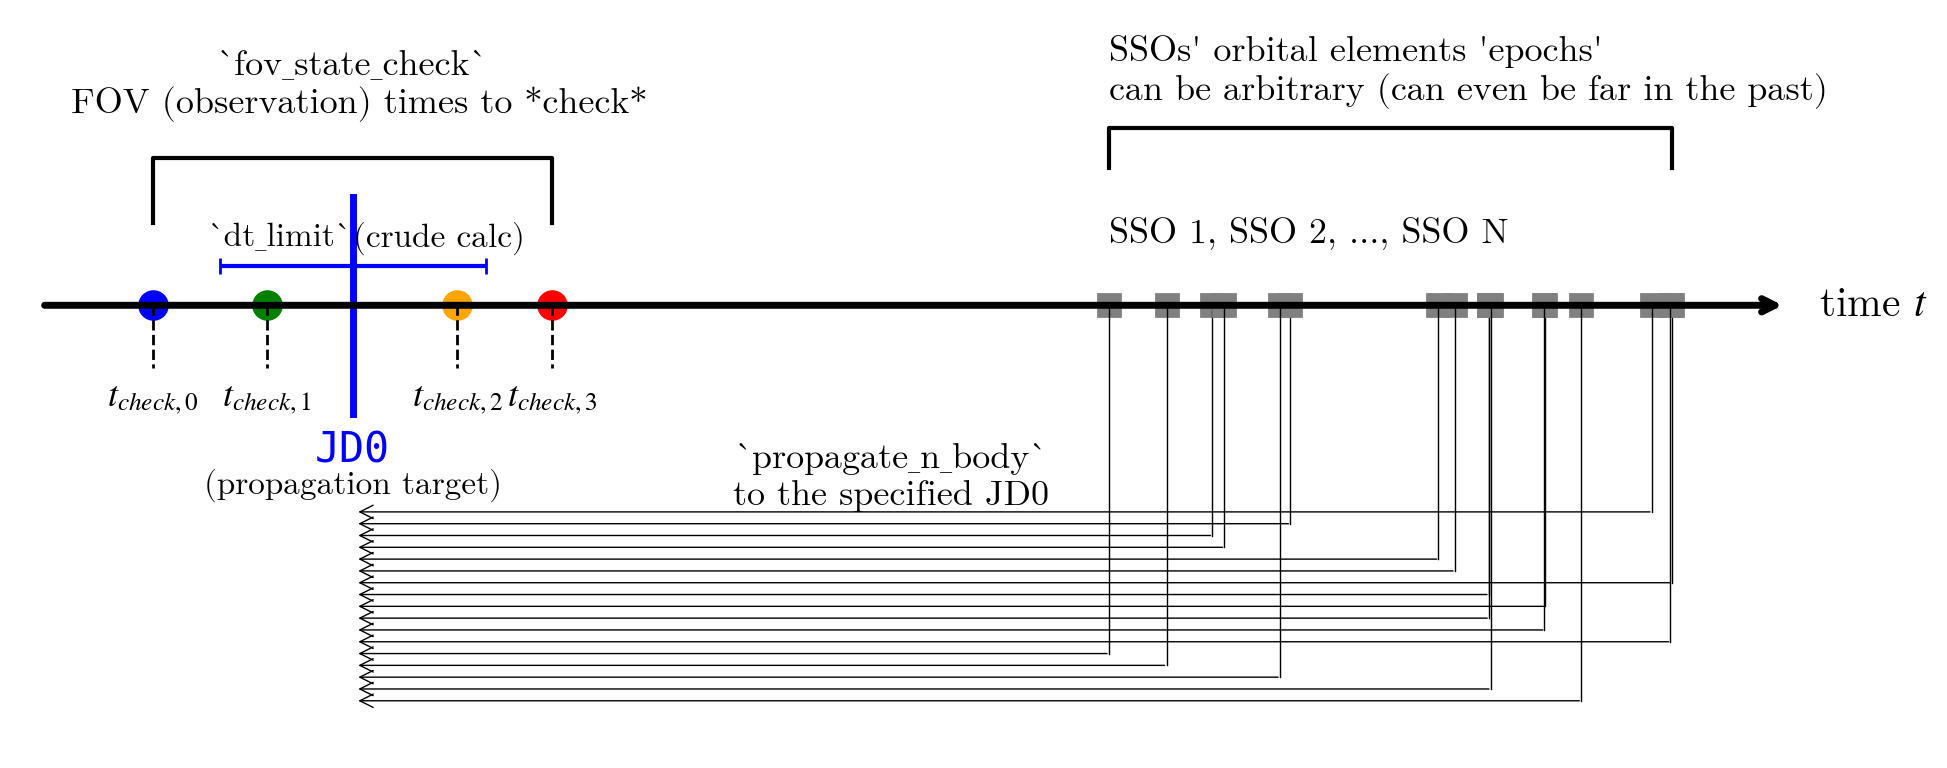

In [ ]:
import numpy as np
from IPython.core.interactiveshell import InteractiveShell
from matplotlib import pyplot as plt

%config InlineBackend.figure_format = 'retina'
# %matplotlib notebook
InteractiveShell.ast_node_interactivity = 'last_expr'

# We need to do it in a separate cell. See:
# https://github.com/jupyter/notebook/issues/3385
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'latin modern math', 'font.size':12, 'mathtext.fontset':'stix',
    'axes.formatter.use_mathtext': True, 'axes.formatter.limits': (-4, 4),
    'axes.grid': True, 'grid.color': 'gray', 'grid.linewidth': 0.5,
    'xtick.top': True, 'ytick.right': True,
    'xtick.direction': 'inout', 'ytick.direction': 'inout',
    'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,  # default 2.0
    'xtick.major.size': 4.0, 'ytick.major.size': 4.0,  # default 3.5
    'xtick.minor.visible': True, 'ytick.minor.visible': True
})

# Example schematic locations
t_check = np.array([-0.5, -0.2, 0.3, 0.55])
JD0 = 0.5 * (t_check.min() + t_check.max())

# Many SSO epochs
N_sso = 17
t_sso = np.random.RandomState(12345).uniform(2., 3.55, N_sso)

fig, ax = plt.subplots(figsize=(10, 4))

# Main time axis
ax.annotate(
    "", xy=(3.8, 0), xytext=(-0.8, 0),
    arrowprops=dict(arrowstyle="->", lw=2.5, color="black")
)
ax.text(3.88, 0, r"time $t$", va="center", ha="left", fontsize=15)

# Check times
check_colors = ["b", "g", "orange", "r"]
for i, (t, c) in enumerate(zip(t_check, check_colors)):
    ax.plot(t, 0, "o", ms=10, color=c)
    ax.plot([t, t], [0, -0.32], "--", lw=1, color="black")
    ax.text(t, -0.40, rf"$t_{{check,{i}}}$", ha="center", va="top", fontsize=13)

# JD0 as midpoint of check times
ax.plot([JD0, JD0], [-0.55, 0.55], lw=2.5, color="b")
ax.text(JD0, -0.63, "JD0", ha="center", va="top",
        fontsize=15, color="b", fontfamily="monospace")
ax.text(JD0, -0.83, "(propagation target)", ha="center", va="top", fontsize=12)

# Bracket over fov_state_check group
y_br = 0.75
ax.plot(
    [t_check.min(), t_check.min(), t_check.max(), t_check.max()],
    [0.42, y_br, y_br, 0.42],
    color="black", lw=1.5
)
ax.text(
    JD0, y_br + 0.18,
    "`fov_state_check`\n FOV (observation) times to *check*",
    ha="center", va="bottom", fontsize=13,
)

# Propagation-arrow y positions
y0 = -1.05
dy = -0.06
y_arrows = y0 + dy * np.arange(N_sso)

# SSO epochs: all gray, no individual text labels
for t, y in zip(t_sso, y_arrows):
    ax.plot(t, 0, "s", ms=8, color="gray")
    ax.plot([t, t], [0, y], "-", lw=0.5, color="black")

# Compact SSO label
ax.text(
    t_sso.min(), 0.28,
    r"SSO 1, SSO 2, ..., SSO N", va="bottom", fontsize=13
)

# Bracket over SSO epochs
y_sso = 0.90
ax.plot(
    [t_sso.min(), t_sso.min(), t_sso.max(), t_sso.max()],
    [0.7, y_sso, y_sso, 0.7],
    color="black", lw=1.5
)
ax.text(
    np.min(t_sso), y_sso + 0.1,
    "SSOs' orbital elements 'epochs'\ncan be arbitrary (can even be far in the past)",
    ha="left", va="bottom", fontsize=13
)

# Separate propagation arrows from each SSO epoch back to JD0
for t, y in zip(t_sso, y_arrows):
    ax.annotate(
        "", xy=(JD0, y), xytext=(t+0.01, y),
        arrowprops=dict(arrowstyle="->", lw=0.5, ls="-", color="black")
    )

ax.errorbar(
    JD0, y0 + 1.25, xerr=0.35, fmt="", capsize=3, ms=10, color="b",
)
ax.text(JD0, y0 + 1.35, "`dt_limit`", ha="right")
ax.text(JD0, y0 + 1.35, "(crude calc)", ha="left")

ax.text(
    0.5 * (JD0 + t_sso.mean()), -0.7,
    "`propagate_n_body`\nto the specified JD0",
    ha="center", va="top", fontsize=13,
)

# Clean up
ax.set_xlim(-0.85, 3.95)
ax.set_ylim(-2.25, 1.45)
ax.axis("off")

plt.tight_layout()
plt.show()

Note that function names in `skyloc` is intentionally the same as `kete`, because what it does is merely the same with a few convenience features.

The orbital-element solution for each SSO is typically provided at its own **epoch**, which may differ from object to object depending on factors such as the timing of the most recent observations. The **epoch** specifies the time at which the reported (Keplerian) orbital elements are valid. Because orbital elements evolve under gravitational perturbations in an N-body system, the elements corresponding to one epoch are generally not identical to those at another epoch (e.g., at `JD0`).

(Since observations are generally made before the analyses, I made this example such that SSO epochs are in the future - opposite is definitely possible and also common).

To enable a consistent comparison among all objects, `skyloc` requires that the orbital elements of every SSO are first propagated to a common reference epoch (function: `propagate_n_body`), denoted as `JD0`. After this step, all objects have orbital states defined at the same epoch. 

The field-of-view (FoV) check (function: `fov_state_check` for moving objects, `fov_static_check` for fixed objects) is then performed for specific observation times, denoted as t_check in the diagram. `JD0` is generally chosen to be near these observation times to minimize further propagations from JD0 to observation time. For each observation time, the orbital state of each object is propagated from `JD0` to that observation time. The resulting position is compared with the FoV geometry to determine whether the object lies within the instrument’s field of view. `dt_limit` is used here to accelerate calculation when `|t_check - JD0| < dt_limit[day]`. For such short dt, it uses two-body Keplerian, not full N-body.

In summary, the procedure consists of two propagation stages:

1. Propagate each object’s orbital solution from its native epoch to the common reference epoch `JD0`.
2. Propagate the object from `JD0` to each observation time at which the FoV check is performed.

This approach avoids repeatedly propagating from many different orbital-element epochs and provides a uniform reference state for all SSOs.

In [1]:
import kete
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS

import skyloc as sloc

sloc.set_log_level("INFO")  # "DEBUG" = verbose, "INFO" = normal, "WARNING" = quiet

* `skyloc.fetch_orb`: By default, ``drop_impacted=True, drop_unreliable=True``, i.e., objects impacted Earth prior to 2025 and those with unreliable orbits (disappeared or lost comets, unknown orbital solution date, absolutely no magnitude information, etc). The majority of comets (~80%, mostly historic ones) will be removed by this.

In [2]:
# Download the orbit information file from JPL SBDB
# ~ 4-10min for the first time, ~10s for subsequent runs.
orb, m_ng = sloc.fetch_orb(
    output="orb_sbdb.parq",
    update_output=999,  # days - if output's last-modified is older than this, it will be updated
    filters=[
        # ("kind", "not in", ("au")),
        # ("kind", "in", ("cu", "cn")),
        ("condition_code", "in", ["0", "1"]),
    ]
)
print("Number of objects, number of columns: ", orb.shape)
print("latest 'soln_date' [US/Pacific]     : ", orb["soln_date"].max())

# Just for printing purposes...
n_ng = np.sum(m_ng)

print("Number of     grav objects          : ", orb.shape[0] - n_ng)
print("Number of non-grav objects          : ", n_ng)

2026-06-10T22:00:08.81+0900 [INFO] skyloc.query: Loaded 1189570 objects (36 columns)


Number of objects, number of columns:  (1189570, 36)
latest 'soln_date' [US/Pacific]     :  2025-06-09 07:42:01
Number of     grav objects          :  1188905
Number of non-grav objects          :  665


## 1. Case of Ground Stations

First, load the test file 

In [3]:
hdu = fits.open("testdata/oph_003_20250715061809_wcs.fits")[0]

# This FITS has JD at the *end* of the exposure, so we need to adjust it:
jd_mid = hdu.header["JD"] - float(hdu.header["EXPTIME"]) / 86400 / 2
print("JD at the middle of the exposure: ", jd_mid)

# make WCS
wcs = WCS(hdu.header)
print("WCS: ", wcs)

JD at the middle of the exposure:  2460871.7620833335
WCS:  WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 254.937995554 -0.256453685105
CRPIX : 2048.5 2048.5
CD1_1 CD1_2  : -0.000823657486656 3.86751823546e-05
CD2_1 CD2_2  : 3.8319380249e-05 0.000823907558298
NAXIS : 4096  4096


If you are lucky enough to have FITS files from an observatory that has the IAU observatory code, you can just use it. It is very simple so I just copied from [kete's docs](https://dahlend.github.io/kete/auto_examples/getting_started.html#field-of-views):

In [4]:
# make kete state
observer = kete.spice.mpc_code_to_ecliptic("Palomar Mountain", jd_mid)
print(observer)

State(desig="675", jd=2460871.7620833335, pos=[0.39189832690205717, -0.9378229865777284, 8.933437949152777e-5], vel=[0.015818187970356216, 0.006563016793228195, -1.9992163574401965e-6], frame=Ecliptic, center_id=10)


But more frequently, you will not have observatory code. Then you can use observatory information following the kete notation:

In [5]:
observatory = (37.071667, 240.58861, 1.400)  # lat, lon in deg, height in km

observer = kete.spice.earth_pos_to_ecliptic(jd_mid, *observatory, name="SRO")
print(observer)

State(desig="SRO", jd=2460871.7620833335, pos=[0.39189681098679247, -0.9378206039626024, 9.075946481989258e-5], vel=[0.01580798729092634, 0.006554231878741213, 1.8375394994441517e-6], frame=Ecliptic, center_id=10)


Then make the FOV object in kete:

In [7]:
fov = kete.fov.RectangleFOV.from_wcs(wcs, observer)
print(fov)

GenericRectangle(pointing=Vector([-0.259881393334, -0.887721372535, 0.380016349838], Ecliptic), observer=State(desig="SRO", jd=2460871.7620833335, pos=[0.39189681098679247, -0.9378206039626024, 9.075946481989258e-5], vel=[0.01580798729092634, 0.006554231878741213, 1.8375394994441517e-6], frame=Ecliptic, center_id=10), lon_width=3.3763728873296674, lat_width=3.377464375939519)


Now, check which SSOs are in the FoV. There are several ways to do this, as in kete's official docs. In `skyloc`, you wrap the FOV(s) in a `FOVCollection` and use `SSOLocator`:

1. `propagate_n_body`: N-body propagate all orbits to the (mean) JD of the FOVs.
2. `fov_state_check`: find which objects actually fall inside each FOV.

`non_gravs=True` automatically applies non-gravitational accelerations to the objects that have such parameters.

In [11]:
# 1.2M objs: ~15s on MBP 14" [2024, macOS 26.5, M4Pro(8P+4E/G20c/N16c/48G)]
sl1 = sloc.SSOLocator(
    fovs=sloc.FOVCollection([fov]),
    orb=orb,
    non_gravs=False
)
sl1.propagate_n_body(include_asteroids=False, jd0=np.mean)
sl1.fov_state_check(include_asteroids=False, dt_limit=3.)

2026-06-10T22:03:10.83+0900 [INFO] skyloc.core: Propagated 1189565 states to JD 2460871.76
2026-06-10T22:03:10.98+0900 [INFO] skyloc.core: FOV check: 137 objects in 1 FOVs


### Get the ephemerides

`calc_ephems` computes the full geometry for every (object, FOV) pair and stores it in `sl1.eph` as a `DataFrame`. Columns include `ra`/`dec`, ecliptic (`hel_ecl_*`, `obs_ecl_*`) and galactic (`glx_lon`, `glx_lat`) coordinates, distances (`r_hel`, `r_obs`), phase angle `alpha`, sky-motion rates, and `vmag`.

In [9]:
sl1.calc_ephems()
sl1.eph

,desig,alpha,r_hel,r_obs,hel_ecl_lon,hel_ecl_lat,obs_ecl_lon,obs_ecl_lat,glx_lon,glx_lat,...,dec,racosdec_rate,dec_rate,sky_motion,sky_motion_pa,sun_target_pa,vmag,jd_tdb,jd_utc,obsid
0,17006,19.912742,2.111094,1.266470,-89.030972,12.942826,-107.694086,21.918111,18.116171,25.501743,...,-0.520766,-0.145353,-0.264841,0.302106,-151.240632,120.640527,16.512867,2.460872e+06,2.460872e+06,SRO
1,5280,19.778067,2.102829,1.252984,-88.741195,12.510030,-107.283223,21.312580,17.674891,24.907475,...,-1.167619,-0.096851,-0.215985,0.236706,-155.847783,120.229881,16.966845,2.460872e+06,2.460872e+06,SRO
2,7889,24.702241,1.691054,0.805780,-83.467525,10.809762,-105.898612,23.171658,20.116153,24.484233,...,0.533848,-0.992619,-1.510819,1.807725,-146.694798,122.507311,17.106176,2.460872e+06,2.460872e+06,SRO
3,15356,17.496673,2.377973,1.545491,-90.914459,13.953075,-107.380680,21.774341,18.100212,25.177577,...,-0.698369,-0.265575,-0.357213,0.445119,-143.370523,120.623118,17.396145,2.460872e+06,2.460872e+06,SRO
4,18955,14.714640,2.731988,1.899730,-91.522660,15.224325,-105.224593,22.184718,19.402587,23.516823,...,-0.513819,-0.249765,-0.106083,0.271360,-113.012389,121.862202,17.792897,2.460872e+06,2.460872e+06,SRO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
132,2017 AN47,15.294020,2.676042,1.849940,-91.293132,16.259228,-105.424423,23.888809,21.028754,24.370614,...,1.200161,-0.374499,-0.260562,0.456226,-124.828723,123.380336,23.429934,2.460872e+06,2.460872e+06,SRO
133,2021 PF186,10.505297,3.801156,2.993956,-95.574161,16.744148,-105.517026,21.453275,18.553789,23.464632,...,-1.212556,-0.315788,-0.231525,0.391569,-126.247506,121.034659,23.628364,2.460872e+06,2.460872e+06,SRO
134,2015 RT358,11.068944,3.634998,2.828424,-95.424470,16.609182,-105.910968,21.550590,18.486275,23.838780,...,-1.076313,-0.295858,-0.133469,0.324570,-114.281252,120.971906,23.638731,2.460872e+06,2.460872e+06,SRO
135,2022 WZ13,10.742066,3.821386,3.029317,-97.191613,16.490416,-107.501449,20.980116,17.248586,24.957645,...,-1.473516,-0.270962,-0.129582,0.300353,-115.558476,119.842344,23.864225,2.460872e+06,2.460872e+06,SRO


### Pixel positions on the image

Given the image WCS, convert each object's `(ra, dec)` to pixel `(x, y)`. `all_world2pix_infov` also returns a boolean mask of which objects actually land on the detector (within `bezels` of the edges).

In [10]:
eph = sl1.eph
xypos, infov = sloc.all_world2pix_infov(wcs, eph[["ra", "dec"]], 0)
eph["x"] = xypos[:, 0]
eph["y"] = xypos[:, 1]
eph["infov"] = infov

# Objects that actually land on the detector:
eph.loc[eph["infov"], ["desig", "ra", "dec", "x", "y", "vmag"]]

,desig,ra,dec,x,y,vmag
0,17006,253.621739,-0.520766,3627.118158,1653.106019,16.512867
1,5280,253.928610,-1.167619,3218.554258,886.396052,16.966845
2,7889,255.413078,0.533848,1516.855436,3031.184621,17.106176
3,15356,253.893322,-0.698369,3287.983991,1453.209508,17.396145
4,18955,255.926112,-0.513819,835.457016,1791.521322,17.792897
...,...,...,...,...,...,...
132,2017 AN47,255.922400,1.200161,937.563044,3866.647594,23.429934
133,2021 PF186,255.578972,-1.212556,1216.171404,925.356352,23.628364
134,2015 RT358,255.224996,-1.076313,1652.980749,1070.493664,23.638731
135,2022 WZ13,253.686918,-1.473516,3494.018251,501.647949,23.864225


### Need higher accuracy?

The single-pass integration above is fast and already accurate to ~a few arcsec for the vast majority of cases.

For sub-arcsec accuracy (refined N-body pass, optionally including the major asteroids as perturbers), 
1. Option #1: Use `non_gravs=True` and `include_asteroids=True`, and tune `dt_limit` in the above steps.
  * The number of SSOs with non-grav parameters is currently small (~1,000), so turning it on will have small impact when you do >1M objects.
  * The `include_asteroids` will increase the runtime for a lot of objects, so the total runtime will increase.
  * The `dt_limit` is the maximum allowed time step (in days) for two-body approximation. The default ``3.`` is already quite accurate, but you may decrease this for much higher accuracy. However, for such cases, the uncertainty from orbital elements may already be larger than the error from two-body approximation, so it may not be worth the extra runtime.
2. Option #2: Use the convenience function `sloc.locator_twice`, demonstrated in the `01-*` notebooks.